# 1. zárthelyi dolgozat, B) változat (2025. 06. 03.)

**Az első zárthelyi dolgozat során egy egyszerű Multi-layer Perceptron (MLP) típusú neuronhálót kell betanítani és kiértékelni egy bináris klasszifikációs feladaton a PyTorch könyvtár segítségével.**

A zárthelyi több részfeladatból áll (A - I), melyek egymásra épülnek. A feladat automatikus tesztelőszkripttel rendelkezik és vizsgálja az egyes részfeladatokra adott megoldások helyességét. Éppen ezért, **ne változtasd meg a notebook struktúráját**, ne szedd több részre, illetve ne módosítsd a megírt részeket, csak a megoldásaidat írd be a megfelelő helyre, különben nem fogjuk tudni értékelni! A megoldások az `# Implement your solution BELOW` és `# Implement your solution ABOVE` sorok közé írandók. Ha a megoldott részfeladatok futtatásakor a "Tester: .... OK" felirat megjelenik, a tesztelőszkript nem talált hibát a megoldásban, azonban, a tesztelő nem teljeskörű, nem vesz észre mindenfajta hibát.

**A feladatban elérhető klasszifikációs pontosság:** 85-90% körüli (bináris) accuracy érhető el a feladat helyes megoldásával. (A címke kategóriák nagyjából kiegyensúlyozottak lesznek.) Ha ennél jelentősen rosszabb, vagy jelentősen jobb az eredmény, amit a neuronháló legfeljebb elér a teszthalmazon, akkor hibára lehet gyanakodni és meg kell próbálni azt megtalálni: a részfeladatok eredményeit össze lehet például vetni a feladatok szövegével és az eredeti, szöveges fájlban letöltött adatbázissal.

**A megoldott feladatsor beadása:** A kész megoldást tartalmazó notebookot (.ipynb) fájlként kell feltölteni a Canvas-ban, az "1. zárthelyi dolgozat pótlás" beadási felületén.

**További szabályok:**
- Kérjük a notebook szerkezetét nem módosítani és nem szétszedni külön feladatok szerint!
- A zárthelyi megoldásához, kizárólag, a Canvas feladatból letöltött .zip fájl tartalma és a Canvasban a saját profilból, már a ZH kezdetekor is elérhető tartalom használható fel. Kommunikáció csak az oktatókkal engedélyezett a ZH ideje alatt.

**Rendelkezésre álló idő:** 150 perc

**Értékelés:** Legfeljebb 40 pont gyűjthető: lásd a részfeladatokra adható pontokat az egyes feladatoknál. Minimum 20 pontot el kell érni ezen a zárthelyin ahhoz, hogy az sikeresnek legyen tekinthető.

**Kikötés:** Ahol csak lehet, hatékony, vektorizált megoldásokat várunk. Nagy számú iterációt (50+) végrehajtó ciklus és hasonló, nem hatékony konstrukció a kódban pontlevonást eredményezhet. Részletek a "HF1 GYIK" Canvas fórumon. Kivételek, ahol büntetés nélkül használható hosszabb ciklus:
- Az A) feladatban.
- A háló betanításánál a tanítási/validációs/teszt loopban, akár epoch-ok, akár batch-ek felsorolására.
- Az I) feladatban a teszt-iterátorból kapott batch-ek felsorolására.


---

Tesztelő szkript letöltése, importok.

In [88]:
# Use with local tester (./annbsc25_p1_zh1b_tester.py) & local database file (./winequality-white_noisy25zh1b.csv)

import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

from annbsc25_p1_zh1b_tester import Tester
print("sikeres importok")

sikeres importok


**Információ az adatbázisról**:
Az adatbázis az UCI Machine Learning Repository "Wine quality" adatbázisa alapján készült. Az adatbázis különböző fehérborok kémiai tulajdonságait tartalmazza (első tizenegy oszlop), valamint öt borszakértő, szubjektív, kóstolás alapján adott értékelését (1-9) a borokra (a maradék öt oszlop, a végén). Egy-egy sorban egy-egy fajta bor adatai találhatók meg.
A zárthelyi dolgozat keretében, **megtanuljuk megkülönböztetni azokat a borokat, melyek minőségét a szakértők nagyjából hasonló pontszámmal értékelik ("Szokványos borok") és azokat a borokat, melyek nagy mértékben megosztják a szakértőket, vagyis nagyon különböző pontszámokat kapnak tőlük ("Furcsa borok").** Az adatbázisban rendelkezésre álló borokat ebbe a két kategóriába fogjuk besorolni, majd ezek megkülönböztetését tanuljuk meg egy neuronhálóval.

A tesztelőszkript letölti a szöveges formában tárolt adatbázist és elhelyezi a `content` sztringben. Alább, kiírjuk a hosszát és az első 500 karaktert is a sztringből. Az adatbázis fájlok egy-egy sora adja meg az egy-egy mintaelemhez tartozó változók értékeit. A sorokban az egyes változókhoz tartozó értékek pontosvesszővel vannak elválasztva. Az adatbázis első sora a változók neveit tartalmazza.


In [89]:
tester = Tester()
content = tester.get_dataset_content()

print("Number of characters in dataset:", len(content))
print(content[:500])


Number of characters in dataset: 298181
"fixed acidity","volatile acidity","citric acid","residual sugar","chlorides","free sulfur dioxide","total sulfur dioxide","density","pH","sulphates","alcohol","score1","score2","score3","score4","score5"
7,0.27,0.36,20.7,0.045,-,-,1.001,3,0.45,8.8,5,6,7,4,4
6.3,0.3,0.34,1.6,0.049,-,132,0.994,3.3,0.49,9.5,3,1,9,6,9
8.1,0.28,0.4,6.9,0.05,30,97,0.9951,3.26,0.44,10.1,7,6,6,8,5
7.2,0.23,0.32,8.5,0.058,-,186,0.9956,3.19,0.4,9.9,6,4,8,6,8
7.2,0.23,0.32,8.5,0.058,-,186,0.9956,3.19,0.4,9.9,8,7,6,6,6
8.1


## **A**: Az adatbázis betöltése - 3 pont

A feladatod, hogy **átalakítsd a `content` sztringet az adatbázis változóinak értékeit tartalmazó NumPy tömbbé.** A tömbök adattípusa np.float32 (lebegőpontos) legyen! A változók értékeit helyezd el a `dataset_missing_input` (n_mintaelem, n_változó) alakú tömbben!  Az input változókat és címkéket később választjuk majd szét.

Az adatbázis helyenként hiányzó értékeket tartalmaz: a kémiai adatok egy része nem volt elérhető az adatbázis rögzítésekor. Hiányzó értékek tetszőleges oszlopban lehetnek. A hiányzó értékek a '-' (kötőjel/mínuszjel) karakterrel vannak helyettesítve a `.csv` fájlban. A hiányzó értékeket kezelned kell és fel kell ismerned beolvasás közben: a hiányzó értékek helyére a `dataset_missing_input` tömbben `np.nan` (Not-a-Number) értékek kell, hogy kerüljenek!


In [90]:
# implement your solution BELOW

lines = content.split('\n')
lines_segmented = [line.split(',') for line in lines]   # list (lines) of lists (words in each line)
attr_names = lines_segmented[0]
data = lines_segmented[1:-1]
data = [[np.nan if item == "-" else float(item) for item in line] for line in data]
dataset_missing_input = np.array(data, dtype=np.float32)
print(dataset_missing_input.shape)


# implement your solution ABOVE

tester.test('dataset_load', dataset_missing_input)

(4898, 16)
Tester: Dataset loading OK


## **B**: A hiányzó input értékek kezelése - legfeljebb 5 pont

NaN értékekkel nem fogunk tudni tovább dolgozni, hiszen a legtöbb NumPy/PyTorch művelet nem támogatja őket és bármilyen tömbre, melyben legalább egy NaN érték található, ezen műveletek kimenete is NaN lesz, így például a neuronhálónk becslése és költsége is. Utóbbi megakadályozza, hogy a hálót gradiens módszerrel optimalizáljuk. Éppen ezért, a hiányzó adatokat reprezentáló NaN értékeket az alábbi módon fogjuk eltüntetni:



### **1. (könnyebb) opció** - 1 pont

**Helyettesítsd az összes NaN értéket nullával a tömbben**, majd add értékül a tömböt a `dataset` változónak!

### **2. (kissé nehezebb) opció** - 5 pont

- Elsőként, dobd el azokat a változókat (oszlopokat) az adatbázisból, melyekben az értékek több, mint 20 százaléka hiányzik (azaz NaN)!
- Írasd ki az eldobott változók indexét és/vagy nevét! Használj automatikus módszereket!
- Ezt követően, dobd el azokat a borokat (sorokat), melyekben legalább kettő hiányzó (NaN) érték maradt (a súlyosan hiányos oszlopok eldobását követően)!
- Végül, helyettesítsd az összes megmaradt NaN értéket nullával a tömbben!


**Emlékeztető:** `np.nan == np.nan` definíció szerint hamis! Az `np.isnan()` függvény alkalmazható a NaN értékek megkeresésére.



In [91]:
# implement your solution BELOW
not_too_many_nan_cols = np.count_nonzero(np.isnan(dataset_missing_input[:,:]), axis=0) <= dataset_missing_input.shape[0]*0.2 # ez minden egyes ertekre megmondja, nan-e, majd ebbol az arraybol osszeszamoja oszloponkent a true-kat

dataset_without_nan_cols = dataset_missing_input[:,not_too_many_nan_cols].copy()

print("Az eldobott oszlopok neve(i):")
for ind, keep in enumerate(not_too_many_nan_cols):
    if not keep:
        print(attr_names[ind])


not_too_many_nan_rows = np.count_nonzero(np.isnan(dataset_without_nan_cols[:,:]), axis=1) < 2
dataset_without_nan_rows = dataset_without_nan_cols[not_too_many_nan_rows,:].copy()
nan_mask = np.isnan(dataset_without_nan_rows[:,:])
dataset_without_nan_rows[nan_mask] = 0
dataset = dataset_without_nan_rows.copy()

# implement your solution ABOVE

tester.test('dataset_fill_missing', dataset)

Az eldobott oszlopok neve(i):
"free sulfur dioxide"
"total sulfur dioxide"
Tester: Dataset fill missing input: (Dataset shape changed - going for Option#2...)
Tester: Dataset fill missing input: Option #2 OK


## **C**: A két kategóriába tartozó borok különválasztása - 4 + 4 pont

Ebben a feladatban szétválasztjuk - az immár hiányzó értékeket nem tartalmazó adatbázist. Itt definiáljuk a borok két kategóriáját ("Szokványos borok" és "Furcsa borok"), majd az adatbázisban található borokat (az adatbázis sorait) szétosztjuk a két kategóriába. Miután szétválasztottuk a borokat a két kategóriába, az adatbázisból már csak a borok kémiai tulajdonságait (az input változóinkat) tartjuk meg, a borszakértők pontszámaira nincs többé szükségünk.

#### **Alapfeladat**: 4 pont

Készítsd el a `typical_wines_inputs` és `weird_wines_inputs` tömböket, melyek egyikébe besorolunk minden bort az adatbázisból az alábbi feltételek alapján:

- A  `typical_wines_inputs` tömbbe kerüljenek a **"Szokványos borok"** kategóriába tartozó borok. Ezek azok a borok, melyeknél a leggyengébb és legjobb borszakértői pontszámok különbsége kevesebb, mint 3.5!
- A  `weird_wines_inputs` tömbbe kerüljenek a **"Furcsa borok"** kategóriába tartozó borok. Minden olyan bor ide tartozik, amelyik nem került bele a "Szokványos borok" kategóriába.

**A két tömbbe már csak az input változók oszlopai kerüljenek be**, tehát az utolsó öt oszlopot, melyben a borszakértők által adott pontszámok voltak, távolítsd el belőlük! (Maguk a pontszámok az "Extra feladathoz" még kellhetnek, de a későbbiekben nem használjuk már őket.)

#### **Extra feladat**: további +4 pont

Miután megvalósítottad az alapfeladatot, szűrd ki és dobd el a következő feltételeknek megfelelő borokat, a két tömbből:

- Ne kerüljenek be a **"Szokványos borok"** közé azok a borok, melyeknél volt olyan borszakértő, aki túlzottan eltérő pontszámot adott a többiekhez képest: szűrd ki a `typical_wines_inputs` tömbből azokat a borokat, melyeknél van olyan borszakértői pontszám, mely eltér az arra a borra adott pontszámok mediánjától legalább 2.5-el!

- Ne kerüljenek be a **"Furcsa borok"** közé azok a borok, melyeknél túl nagy egyetértés volt a borszakértők értékelése közt: szűrd ki a `weird_wines_inputs` tömbből azokat a borokat, melyeknél legalább négy borszakértő ugyanazt a pontszámot adta!

**Megjegyzés:** Az extra feladatnál kizárólag azok a teljesen vektorizált megoldások érnek teljes pontszámot, melyeknél az egyes feltételeket megvalósító kódok közös utasításokban kezelik a különböző eseteket (például, hogy négy, vagy öt borszakértő pontszáma egyezik-e).


In [121]:
# implement your solution BELOW
difference_in_scores = np.max(dataset[:,-5:], axis=1) - np.min(dataset[:,-5:], axis=1)
small_difference_mask = difference_in_scores < 3.5

typical_wines_inputs = dataset[small_difference_mask,:-5].copy()
weird_wines_inputs = dataset[~small_difference_mask,:-5].copy()
"""
typical_medians = np.median(dataset[small_difference_mask,-5:], axis=1)
radical_typical_mask = np.count_nonzero(np.absolute(dataset[small_difference_mask,-5:] - typical_medians[:,np.newaxis]) > 2.5, axis=1)
typical_wines_inputs = typical_wines_inputs[~radical_typical_mask, :]

agreed_weird_mask = np.unique(dataset[small_difference_mask,-5:], axis=1).shape[0] <= 2

print(np.unique(dataset[small_difference_mask,-5:], axis=1))"""
# implement your solution ABOVE

tester.test('dataset_separate_categories', typical_wines_inputs, weird_wines_inputs)

[[4. 4. 5. 6. 7.]
 [5. 8. 7. 6. 6.]
 [6. 6. 8. 7. 6.]
 ...
 [4. 7. 6. 7. 5.]
 [5. 5. 5. 7. 7.]
 [4. 4. 5. 4. 5.]]
Tester: Dataset separate categories: Alapfeladat OK (Extra feladat missing).


## **D**: Tanító-, validációs- és teszthalmaz szétválasztása - 2 pont

- **Bontsuk fel tanító-, validációs- és teszthalmazra** a két, input-változó értékeket tartalmazó tömböt! Használjunk 60%/20%/20%-os felosztást, mindkét tömbön, egymástól függetlenül! Állítsuk elő így, a

  - `typical_wines_train`, `typical_wines_val`, `typical_wines_test`
  - `weird_wines_train`, `weird_wines_val`, `weird_wines_test`

  nevű, input-változó értékeket tartalmazó tömböket! Előbbi háromba kerül a szétbontott `typical_wines_inputs` (szokványos borok) tömb tartalma, utóbbi háromba a szétbontott `weird_wines_inputs` (furcsa borok) tömb tartalma.


In [93]:
# implement your solution BELOW

typical_wine_count = typical_wines_inputs.shape[0]
typical_wine_val_start = int(typical_wine_count * 0.6)
typical_wine_test_start = typical_wine_val_start + int(typical_wine_count * 0.2)


weird_wine_count = weird_wines_inputs.shape[0]
weird_wine_val_start = int(weird_wine_count * 0.6)
weird_wine_test_start = weird_wine_val_start + int(weird_wine_count * 0.2)

typical_wines_train = typical_wines_inputs[:typical_wine_val_start,:]
typical_wines_val = typical_wines_inputs[typical_wine_val_start:typical_wine_test_start,:]
typical_wines_test = typical_wines_inputs[typical_wine_test_start:,:]


weird_wines_train = weird_wines_inputs[:weird_wine_val_start,:]
weird_wines_val = weird_wines_inputs[weird_wine_val_start:weird_wine_test_start,:]
weird_wines_test = weird_wines_inputs[weird_wine_test_start:,:]
# implement your solution ABOVE

tester.test('dataset_split', typical_wines_train, typical_wines_val, typical_wines_test, \
                             weird_wines_train,   weird_wines_val,   weird_wines_test)

Tester: Dataset split OK


## **E**: Az adat-iterátorok létrehozása a bináris klasszifikációs feladathoz - 4 pont

A házi feladatokhoz és az előző zárthelyihez hasonlóan, ezúttal is iterátorokkal oldjuk meg a neuronhálónk betanítását. Ebben a részfeladatban **elő kell állítanod három iterátor objektumot** `dataloader_train`, `dataloader_val` és `dataloader_test` néven, melyek az előző részfeladatban elkészített megfelelő részhalmazhoz tartozó "Szokványos", vagy "Furcsa" borokat tartalmazó tömbökből sorolják fel a borokat és elkészítik a hozzájuk tartozó bináris klasszifikációs címkéket!

Mivel bináris klasszifikációs feladatot oldunk meg, **egyetlen valószínűséget fogunk becsülni**, azt, **hogy mekkora valószínűséggel tartozik az egyik, előre kiválasztott kategóriába** az adott borfajta.

A fentiek alapján az iterátorok által visszaadott tenzorok alakja `(batch_size, n_input_vars)` és `(batch_size, 1)` lesz.
- Az első tenzor az adatbázis összes felhasznált változójának értékét tartalmazza a kategóriákba besorolt mintaelemekre `torch.float32` adattípusban. `n_input_vars` az input változók számát adja meg, ezen nem változtattunk az előző feladathoz képest, vagyis ez megegyezik az ott előállított tömbök oszlopainak számával (`shape[1]`).
- A második (címkéket tartalmazó) tenzor a borok kategóriáját fogja tartalmazni (azaz 0 vagy 1 értékeket, `torch.float32` adattípusban - hiszen ezúttal ezeket valószínűségekként értelmezzük).  `batch_size` ezúttal is a kötegben elhelyezett mintaelemek számát adja meg, ez kézzel beállítandó.

Az iterátorok implementációja többféleképpen megoldható, akár kézzel, egyedileg, akár a `torch.utils.data` modul `Dataset` és `DataLoader` osztályai segítségével. Gondoskodj róla, hogy **az egyes kötegekbe várhatóan vegyesen kerüljenek be különböző kategóriájú mintaelemek** (például, az adatbázis **véletlenszerű keverésével**)! Figyelj rá, hogy a borokhoz tartozó input változók és címkék sorrendje ne keveredjen különbözőképpen!

**Vigyázz, az iterátorok által visszaadott tenzorok tartalmát a tesztelőszkript nem képes teljeskörűen ellenőrizni!**

In [94]:
# implement your solution BELOW

class BinaryClassificationDataset(Dataset):
    def __init__(self, typical_wines_split, weird_wines_split):
        wines_split = np.concatenate([typical_wines_split, weird_wines_split], axis=0)
        labels_split = np.concatenate([np.zeros(typical_wines_split.shape[0]), np.ones(weird_wines_split.shape[0])], axis=0)
        permutation = np.random.permutation(wines_split.shape[0])
        wines_split = wines_split[permutation, :]
        labels_split = labels_split[permutation]

        self.xs = torch.from_numpy(wines_split).to(torch.float32)
        self.ys = torch.from_numpy(labels_split[:,np.newaxis]).to(torch.float32)

    def __len__(self):
        return self.xs.shape[0]

    def __getitem__(self, idx):
        x = self.xs[idx]
        y = self.ys[idx]
        return x, y

BATCH_SIZE = 32

train_dataset = BinaryClassificationDataset(typical_wines_train, weird_wines_train)  
val_dataset = BinaryClassificationDataset(typical_wines_val, weird_wines_val)         
test_dataset = BinaryClassificationDataset(typical_wines_test, weird_wines_test) 

dataloader_bincl_train = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
dataloader_bincl_val = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=True)
dataloader_bincl_test = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

xs, ys = next(iter(dataloader_bincl_train))
print(xs.shape)
print(ys.shape)
# implement your solution ABOVE

tester.test('bincl_iter', dataloader_bincl_train, dataloader_bincl_val, dataloader_bincl_test)

torch.Size([32, 9])
torch.Size([32, 1])
Tester: Dataset iterators for binary classification task OK


## **F**: A neuronháló definiálása - 3 pont

**Definiáld a bináris klasszifikációs feladathoz alkalmazandó neuronhálót megvalósító osztályt**, mely az általános `torch.nn.Module` osztály leszármazottja, majd példányosítsd azt és add értékül a `bincl_model` nevű változónak a példányt!

Az új osztálynak mindenképpen meg kell valósítania a `forward(self, x)` tagfüggvényt, mely a neuronhálót (hipotézisfüggvényt) az `x` input tenzorra kiértékeli. A `forward` függvény fogja majd az előbb definiált adat-iterátorból érkező input tenzorokat megkapni és előállítani belőle a címkebecsléseket. Az osztály konstruktorában célszerű a neuronhálónk rétegeit inicializálni.

A neuronháló architektúráját megválaszthatod, de figyelj arra, hogy:
- A háló bináris klasszifikációra legyen alkalmas!
- Úgy válaszd meg a rétegek/paraméterek számát, hogy az képes legyen betanulni az elvárt teszt pontosságig!
- A tanultak alapján, ne legyenek benne redundáns elemek!

**Alkalmazd a dropout technikát** a háló legalább egy pontján! Nem javasolt túl nagy valószínűséget beállítani a változók nullázásához (10-20% elgendő ezúttal). Figyelj oda rá, hogy a dropout csak betanítás közben működjön! (Előadáson volt róla szó.)

In [108]:
# implement your solution BELOW

class MLPBinClassifierModel(nn.Module):

  def __init__(self, input_dim):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_dim, 30),
            nn.ReLU(),
            nn.Linear(30, 20),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(20, 1),
            nn.Sigmoid()
        )

  def forward(self, x):
      return self.layers(x)

bincl_model = MLPBinClassifierModel(input_dim=9)

# implement your solution ABOVE
print("Neuronhalo definialva")
# Pay more attentnion here! No test is provided for this task!

Neuronhalo definialva


## **G**: A háló betanítása bináris klasszifikációs feladatra - 6 pont

- **Tanítsd be a** `bincl_model` **neuronhálót** a tanítóhalmazon a `dataloader_bincl_train` iterátor segítségével és alkalmazd a `dataloader_bincl_val` iterátort a validációhoz! Az iterátorok egyetlen (akár véletlen sorrendben történő) végighaladása a tanító és validációs adathalmazokon határoz meg egy _epoch_-ot.

  Alkalmazd a betanításhoz a bináris klasszifikációkor szokásosan használt **költségfüggvényt**!

  A betanításhoz válassz egy gradiens módszer alapú **optimalizációs algoritmust** a `torch.optim` modulból (pl. `SGD`, `Adam`, `RMSprop`, stb.), majd válassz egy megfelelő **tanulási rátát** is!

- A tanítást az **early stopping** technika állítsa le! Amennyiben adott számú epoch-on keresztül (`patience`) nem javul a validációs költség, érjen véget a betanítás és **állítsuk vissza a `bincl_model` súlyait abból az epoch-ból, amikor a legjobb volt a validációs költség!** Mindez automatikusan történjen!

- **Mérd le minden epoch-ban a tanító- és a validációs halmazon mért költségeket, majd a tanítás végeztével rajzold ki ezeknek az értékeknek a tanítás során való alakulását egy közös grafikonon!** A grafikonok kirajzolásához használhatod például a `matplotlib` könyvtárat. Figyelj rá, hogy a grafikonon jól látszódjanak a görbék közti eltérések a tanítás végén is! Ha szükséges, beállíthatod kézzel, hogy az y tengely melyik részét mutassa a grafikon.

  **A grafikonon legyen jelmagyarázat** (legend), mely megmutatja, melyik görbe írja le a tanítási költséget és melyik a validációs költséget!

- **Számold ki az _accuracy_ (pontosság) metrikát is a teszthalmaz elemein** és add értékül a kapott számot a `test_acc` változónak! Az _accuracy_ metrika a helyesen klasszifikált mintaelemek arányát adja meg. Például, ha 150 mintaelem kategóriájának becslésekor 75 esetben találtuk el a helyes kategóriát, az _accuracy_ értéke 0.5 lesz. Figyelj oda, hogy a bináris klasszifikációval kompatibilis módon számold ezt ki!

- **Válassz néhány mintaelemet a teszthalmazból** (például a `dataloader_bincl_test` iterátor segítségével) és **adj becslést a címkéjükre** az input változók értékei alapján, majd **írasd ki az egyes mintaelemekre a becsült és az igazi címkéjüket kategóriák formájában** (Például: `Prediction: 1, true label: 0`)! Így példákon is láthatjuk, hogy mennyire ad jó becsléseket a neuronhálónk.

- Számolj **konfúziós mátrixot** a teszthalmazon és rajzold ki azt! Figyelj oda **a mátrix megfelelő méretére** (a kategóriák számát tekintve)!



Epoch #0, tr loss: 0.5626421570777893, val loss: 0.480541467666626, tr acc: 0.7316576242446899, val acc: 0.8114919066429138
Epoch #1, tr loss: 0.5142835378646851, val loss: 0.4671323597431183, tr acc: 0.7713994383811951, val acc: 0.8125
Epoch #2, tr loss: 0.49994340538978577, val loss: 0.46784523129463196, tr acc: 0.7832880616188049, val acc: 0.8145161271095276
Epoch #3, tr loss: 0.5024352073669434, val loss: 0.4638870358467102, tr acc: 0.779891312122345, val acc: 0.8145161271095276
Epoch #4, tr loss: 0.49208584427833557, val loss: 0.4584429860115051, tr acc: 0.7890625, val acc: 0.819556474685669
Epoch #5, tr loss: 0.48654404282569885, val loss: 0.4579501748085022, tr acc: 0.7863451242446899, val acc: 0.8145161271095276
Epoch #6, tr loss: 0.48877570033073425, val loss: 0.46238940954208374, tr acc: 0.7839673757553101, val acc: 0.8155242204666138
Epoch #7, tr loss: 0.4858097434043884, val loss: 0.4801858365535736, tr acc: 0.7866848111152649, val acc: 0.7953628897666931
Epoch #8, tr loss:

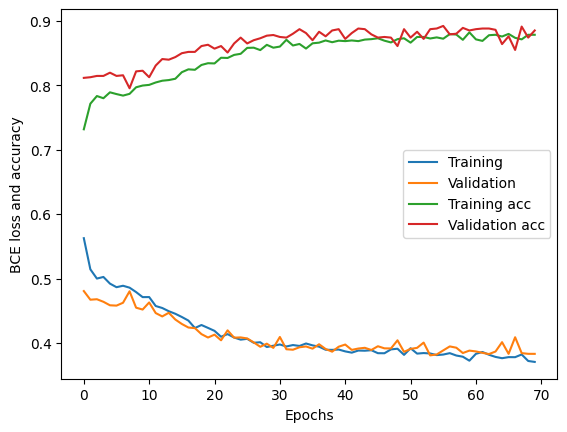

Tester: Binary classification model learning OK


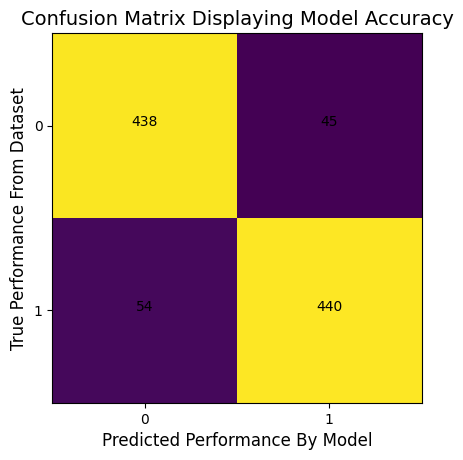

In [109]:
# implement your solution BELOW
import seaborn as sns
#hiperparameterek
epoch_count_cl = 200
patience_cl = 15
lr_cl= 0.001

#fuggvenyek kivalasztasa

loss_fun_cl = nn.BCELoss()
optim_cl = torch.optim.Adam(bincl_model.parameters(), lr=lr_cl)

def acc_cl(y_hat, y_true):                                 # accuracy metric only suitable for binary classification
    # y_hat: (batch_size, 1) single probability, y_true: (batch_size, 1) float32 in {0,1}
    assert y_hat.shape == y_true.shape
    return torch.count_nonzero(torch.round(y_hat) == y_true) / y_hat.shape[0]


#gyujtoket elkeszitem a grafikonokhoz, es a legjobb modell megjegyzesehez
tr_losses_cl = []
tr_accs_cl = []
val_losses_cl = []
val_accs_cl = []
best_cl_model = None
best_val_loss_cl = float('inf')
early_ind_cl = 0


for epoch_ind in range(epoch_count_cl):   #minden egyes epochra:

    bincl_model.train()  #train modba allitom a modellem
    tr_losses_cl_epoch = []   #belso gyujtok letrehozasa
    tr_accs_cl_epoch = []

    for tr_data, tr_labels in dataloader_bincl_train:
        optim_cl.zero_grad()          #felgyulemlett gradiensek nullazasa
        tr_pred = bincl_model(tr_data)     #modellen atkuldom az adatokat, elmentem az outputot (batch_size,3) alakban
        tr_loss = loss_fun_cl(tr_pred, tr_labels)   #koltseg kiszamitasa
        tr_acc = acc_cl(tr_pred,tr_labels)            #accuracy kiszamitasa

        #metrikakat hozzafuzom a belso gyujtohoz
        tr_losses_cl_epoch.append(tr_loss.detach())
        tr_accs_cl_epoch.append(tr_acc)

        #parameterek allistasa
        tr_loss.backward()
        optim_cl.step()


    #tensorra alakitom a belso gyujtoket, majd atlagolom, vegul a kulso gyujtohoz fuzom az atlagukat
    epoch_avg_tr_loss = torch.tensor(tr_losses_cl_epoch).mean()
    tr_losses_cl.append(epoch_avg_tr_loss)
    epoch_avg_tr_acc = torch.tensor(tr_accs_cl_epoch).mean()
    tr_accs_cl.append(epoch_avg_tr_acc)

    #kovetkezik a validacios halmaznak a kiertekelese:
    val_losses_cl_epoch = []
    val_accs_cl_epoch = []

    for val_data, val_labels in dataloader_bincl_val:
        bincl_model.eval()   #kiertekelo modba allitom a modellt
        with torch.no_grad():   #mivel itt nem szamolok gradienst, ezert kikapcsolom a hatekonyitashoz
            val_pred = bincl_model(val_data)   #minden batch atkuldese a modellen, eredmeny elmentese
            val_loss = loss_fun_cl(val_pred, val_labels)   #koltseg kiszamitasa
            val_acc = acc_cl(val_pred, val_labels)   #accuracy kiszamitasa
            val_losses_cl_epoch.append(val_loss)      #nincsen szukseg itt mar a detach-re
            val_accs_cl_epoch.append(val_acc)

    #ismet tensorra alakitom a belso gyujtoket, majd atlagolom, vegul a kulso gyujtohoz fuzom az atlagukat
    epoch_avg_val_loss= torch.tensor(val_losses_cl_epoch).mean()
    val_losses_cl.append(epoch_avg_val_loss)
    epoch_avg_val_acc = torch.tensor(val_accs_cl_epoch).mean()
    val_accs_cl.append(epoch_avg_val_acc)

    print(f"Epoch #{epoch_ind}, tr loss: {epoch_avg_tr_loss}, val loss: {epoch_avg_val_loss}, tr acc: {epoch_avg_tr_acc}, val acc: {epoch_avg_val_acc}")
    
    #a vizsgalatot azzal zarom, hogy ellenorzom, sikerult-e jobb modellt talalni, ha igen, akkor elmentem, de ha nem, akkor megnezem, eleg regen volt-e mar a leallashoz
    if epoch_avg_val_loss < best_val_loss_cl:
        best_val_loss_cl = epoch_avg_val_loss
        best_cl_model = copy.deepcopy(bincl_model)
        early_ind_cl = epoch_ind

    if early_ind_cl + patience_cl < epoch_ind:
        print("Training is terminated by early stopping.")
        break

#visszaterek a legjobb modellhez a train befejeztevel, hogy majd ezen teszteljek:
print("Training finished. Best model weights are restored.")
bincl_model = best_cl_model

#gyujtoket elokeszitem
test_losses_cl = []
test_accs_cl = []
test_labelss = []
test_preds = []

for_visual = True
for test_data, test_labels in dataloader_bincl_test:
    with torch.no_grad():   #gradienszamolast kikapcsolom, mert a teszteleshez nem kell
        test_pred = bincl_model(test_data) #kiertekelek a legjobb modellel
        test_losses_cl.append(loss_fun_cl(test_pred, test_labels))
        test_accs_cl.append(acc_cl(test_pred, test_labels))
        test_labelss.append(test_labels)
        test_preds.append(test_pred)
        if for_visual:   #a par szemlelteto jellegu pelda kiprintelese, ha meg nem tettuk meg
            print("A few true labels and what the model predicted for them:")
            for i in range(5):
              print(f"{float(test_labels[i])}    ~   {round(float(test_pred[i]))}")
            for_visual = False


test_labelss = torch.cat(test_labelss).numpy()    #tensorok keszitese
test_preds = torch.cat(test_preds).numpy()
test_preds = np.round(test_preds)
test_ce = torch.tensor(test_losses_cl).mean()
test_acc = torch.tensor(test_accs_cl).mean()

plt.plot(tr_losses_cl, label='Training')      #tanitasi folyamat diagramja
plt.plot(val_losses_cl, label='Validation')
plt.plot(tr_accs_cl, label='Training acc')
plt.plot(val_accs_cl, label='Validation acc')
plt.xlabel('Epochs')
plt.ylabel('BCE loss and accuracy')
plt.legend()
plt.show()

matrix_cl = confusion_matrix(test_labelss, test_preds) #konfuzios matrixomat letrehozom
plt.imshow(matrix_cl)  #kepkent jelenitem meg
plt.title('Confusion Matrix Displaying Model Accuracy', fontsize=14) #cim
#elokeszitem a tengelyeket:
plt.xlabel('Predicted Performance By Model', fontsize=12) #vizszintes tengely nevadasa
plt.ylabel('True Performance From Dataset', fontsize=12) #fuggoleges tengely nevadasa
plt.xticks(range(2))
plt.yticks(range(2))
for i in range(2):
  for j in range(2):
    value = matrix_cl[i, j]
    plt.text(j, i, value, horizontalalignment = "center") #ertek elhelyezese a megfelelo metszetre
# implement your solution ABOVE

tester.test('bincl_model_learning', test_acc)

## **H**: A legmagabiztosabb becslések kiíratása - 4 pont

Írasd ki a teszthalmaznak azt az öt borát, melyek esetében a neuronháló becslése a leginkább határozott volt! Azaz, azokra a borokra vagyunk kíváncsiak, ahol a becsült valószínűség a legközelebb volt nullához, vagy egyhez (a két esetet együtt kezelve). Fontos, hogy ezúttal nem foglalkozunk azzal, hogy a becslések jók voltak-e (közel voltak-e az igazi címkékhez), csak azzal, hogy magabiztosak voltak-e. Írasd ki a borok összes **input változó-értékét, becsült valószínűségét és igazi címkéjét is**!

**Példa:** a 0.1-es becsült valószínűség magabiztosabb, mint a 0.8, de kevésbé magabiztos, mint a 0.95.

**Példa kimenet:** (nem baj, ha nincs szépen formázva)
```
Most confident predictions:
   #0: [6.4     0.31    0.28    2.5     0.039   0.98946 3.22    0.38    0.     ] -> pred: 0.99981445 v. true: 1.0
   #1: [5.3     0.43    0.11    1.1     0.029   0.99076 3.51    0.48    0.     ] -> pred: 0.0021736 v. true: 1.0
   #2: [5.9     0.54    0.      0.8     0.032   0.99286 3.25    0.36    8.8    ] -> pred: 0.96718264 v. true: 1.0
   #3: [5.9     0.22    0.45    22.6    0.12    0.99636 3.1     0.35    12.8   ] -> pred: 0.035853397 v. true: 0.0
   #4: [5.      0.24    0.19    5.      0.043   0.99438 3.67    0.57    10.    ] -> pred: 0.0372264 v. true: 1.0
```


Teljes pontszám akkor jár, ha ezt az öt bort **közös utasításokkal keresed meg**! Maga a kiíratás természetesen történhet ciklussal!


In [97]:
# implement your solution BELOW (No automatic tests for this task)


most_weird = 






## **I**: A neuronháló döntését leginkább befolyásoló input változók felderítése - 5 pont

Az adatbázis egyes input változóinak fontosságát gyakran meg lehet úgy becsülni, hogy vizsgáljuk, mennyire változik egy betanított neuronháló becslése, ha az adott input változó értékét elfedjük. Ha a becslés nagy mértékben változik, ez jelezheti azt, hogy az adott input változó fontos információkat hordoz a feladat szempontjából. **Ebben a feladatban megvizsgáljuk, hogy melyik input változó mennyire fontos a neuronhálónk számára, annak eldöntéséhez, hogy, egy adott bor mennyire fogja megosztani a borszakértőket** (azaz, hogy a bor "Szokványos"-e, vagy inkább "Furcsa").

Ha korábban nem tetted volna, adj becslést a teszthalmaz elemeire és tárold el az egyes borokhoz becsült valószínűségeket! Ezt követően, egyesével haladj végig az adatbázis input változóin és adj becslést a teszthalmaz összes elemére úgy, hogy a választott input változó minden bornál felülírásra kerül annak a változónak az átlagával! Hasonlítsd össze az így kapott, részben kitakart inputtal végzett becsléseket az eredeti becslésekkel és számolj átlagos abszolút eltérést köztük! Számold ki ezt az átlagos abszolút eltérést minden egyes input változó kitakarása esetén, az eredeti becslésekhez mérve, majd ábrázold az eltéréseket egy oszlopdiagramon!

**Példa eredmény:**

<img src="zh1b_plot_i.png" style="display:inline-block" width='40%'>

A grafikon alapján, tehát, ha a teszthalmaz borainak negyedik (#3 indexű), "residual sugar" nevű változóinak értékét kitakarjuk és felülírjuk a változó átlagával, akkor a betanított neuronhálónk által becsült valószínűségek jelentősen (átlagosan több, mint 0.3-mal) változnak. Ez azt jelzi, hogy a "residual sugar" nevű változó fontos információkat hordoz annak a szempontjából, hogy egy adott bor "Szokványos"-e, vagy inkább "Furcsa".

**Megjegyzés:** A változók neveit nem szükséges ábrázolnod a grafikonon.

In [98]:
# implement your solution BELOW (No automatic tests for this task)







